# RSM8413: Machine Learning Analytics 
## Group Assignment #2 - eBay Auction Decision Trees
*Team 6 Python Code*

### **[1]: Data Preprocessing**

In [35]:
import pandas as pd

ebay_df = pd.read_excel("ebayAuctions.xlsx", sheet_name="eBay auctions"usecols="A:H")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (4235357247.py, line 3)

In [ ]:
ebay_df.head()

#### 1A: Initial Preprocessing

First, we check for any null rows in our data. We take the sheet in the Excel file with the data (eBay Auctions) and only take columns A:H to ensure we don't retrieve other unnamed columns.

In [ ]:
# number of nulls in each column
ebay_df.isnull().sum()

# show null value rows
print(ebay_df[ebay_df.isnull().any(axis=1)].to_string())

After referencing the dataset, the 3 rows that are null are the last 3 rows are aggregations of the data itself and is not part of the dataset. Therefore, it is just a formatting issue and can be dropped. 

In [ ]:
clean_ebay_df = ebay_df.dropna().copy()

clean_ebay_df.isnull().sum()

In [ ]:
# check for duplicate rows

# we note that there are duplicate rows. However, there is no ID column to conclude whether or not the auctions are truly repeated. 
# since there is no further identifier, we keep the duplicates. 

clean_ebay_df[clean_ebay_df.duplicated(keep=False)]

In [36]:
# standardize column names 
# lower case + underscore for 2 words, get rid of other characters
clean_ebay_df.columns = (clean_ebay_df.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True)
                         .str.replace('?', '', regex=False)
                         .str.lower())
clean_ebay_df.competitive.value_counts()

competitive
1.0    1066
0.0     906
Name: count, dtype: int64

#### 1B: Split Train/Test Data

In [37]:
from sklearn.model_selection import train_test_split

features = ["category", "currency", "seller_rating", "duration", "end_day",
            "close_price", "open_price"]

X = clean_ebay_df[features].copy()
y = clean_ebay_df["competitive"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nData types:")
print(X.dtypes)

Predictor shape: (1972, 7)
Target shape: (1972,)

Data types:
category          object
currency          object
seller_rating    float64
duration         float64
end_day           object
close_price      float64
open_price       float64
dtype: object


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1183, 7)
Testing set: (789, 7)


We  split the train/test set into 60% (1183 observations) training and 40% test (789 observations). 
We set the fixed random state to 42 to ensure reproducibility of every run. 

We'll use the training set to perform any further preprocessing steps and visualizations to grasp a better understanding of the variable distributions. 

#### 1C: Predictor Distribution Check

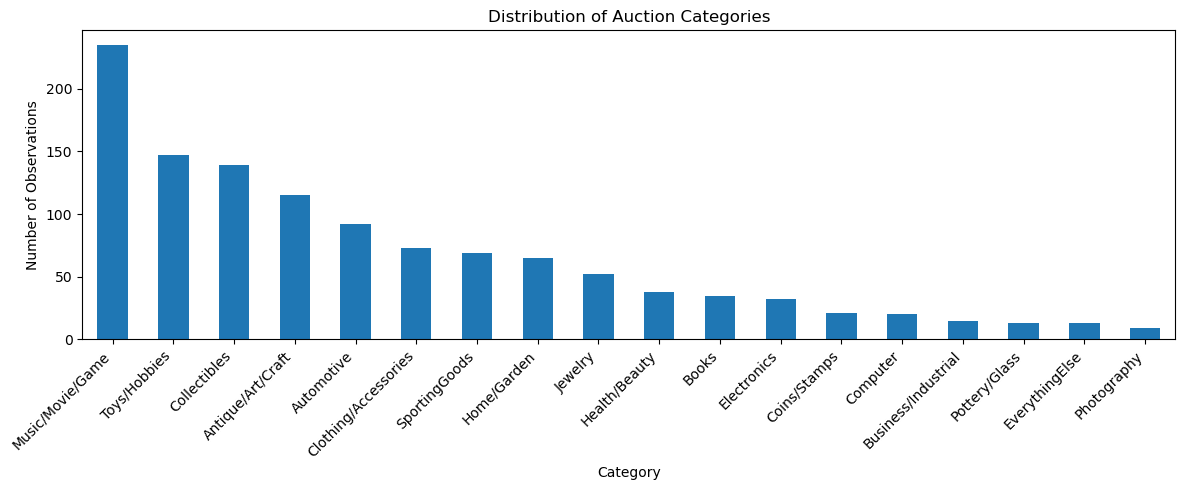

In [39]:
# Category
import matplotlib.pyplot as plt

X_train["category"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Auction Categories")
plt.xlabel("Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

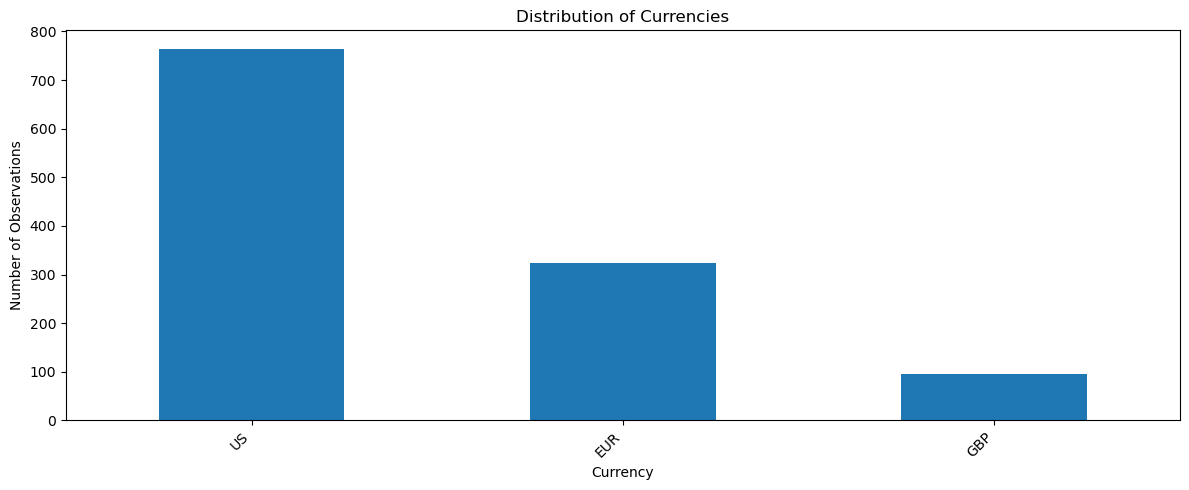

In [40]:
# currency
X_train["currency"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Currencies")
plt.xlabel("Currency")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count     1183.000000
mean      3544.847844
std       6058.473199
min          0.000000
25%        578.000000
50%       1719.000000
75%       3380.000000
max      37727.000000
Name: seller_rating, dtype: float64
skew: 3.231030495585378
missing: 0


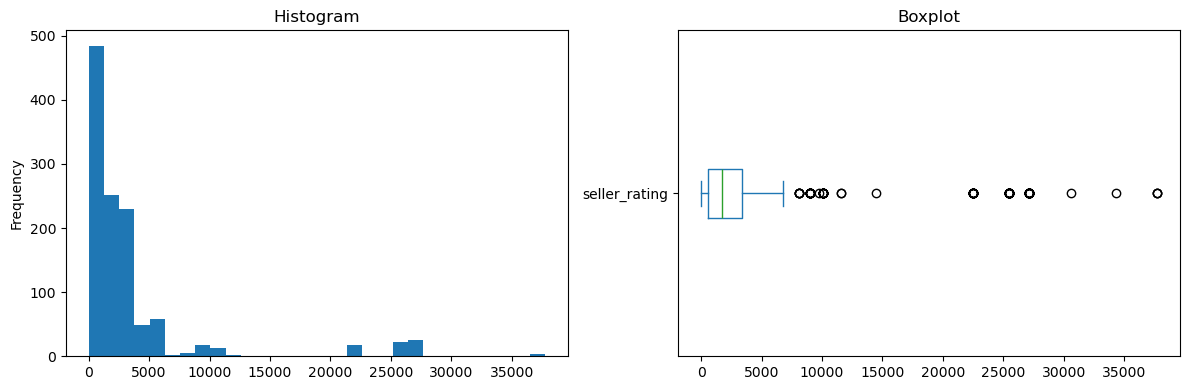

In [41]:
# seller rating 
col = X_train["seller_rating"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

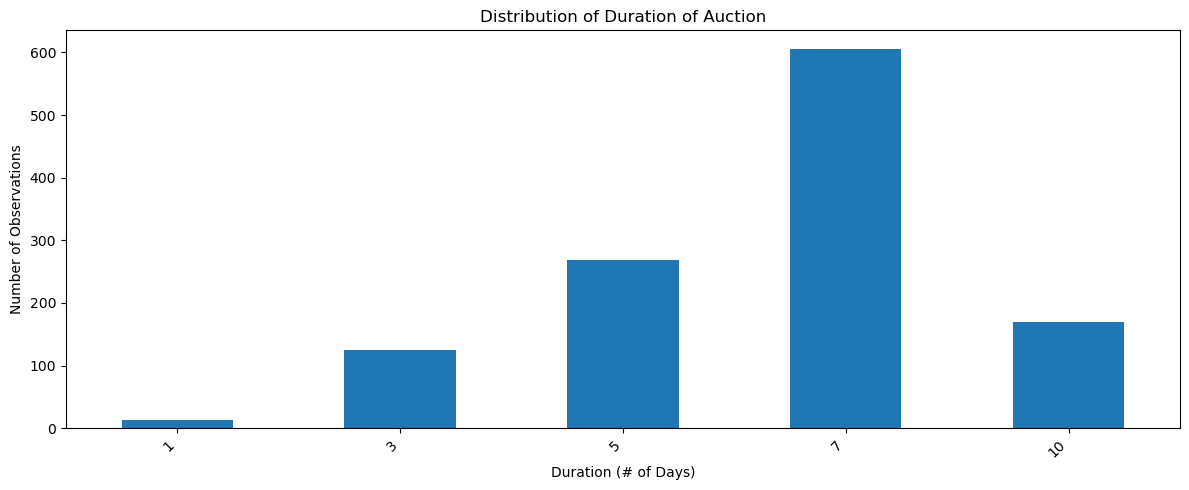

In [42]:
# duration
duration_order = [1, 3, 5, 7, 10]

X_train["duration"].value_counts().reindex(duration_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Duration of Auction")
plt.xlabel("Duration (# of Days)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

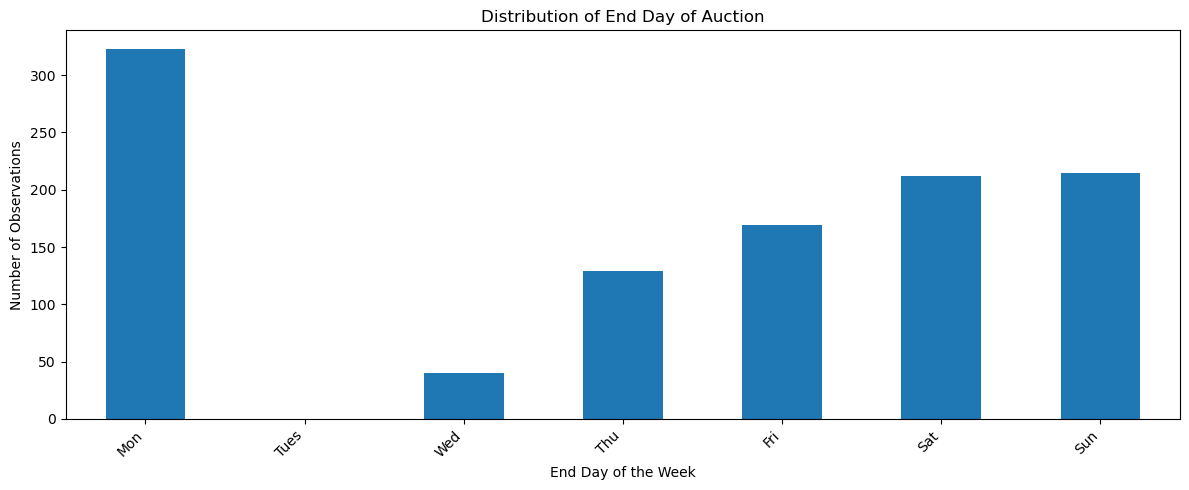

In [43]:
# end day 
day_order = ['Mon', 'Tues', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
X_train["end_day"].value_counts().reindex(day_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of End Day of Auction")
plt.xlabel("End Day of the Week")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count    1183.000000
mean       35.204573
std        86.799829
min         0.010000
25%         4.420000
50%         9.990000
75%        27.000000
max       999.000000
Name: close_price, dtype: float64
skew: 6.190841521267898
missing: 0


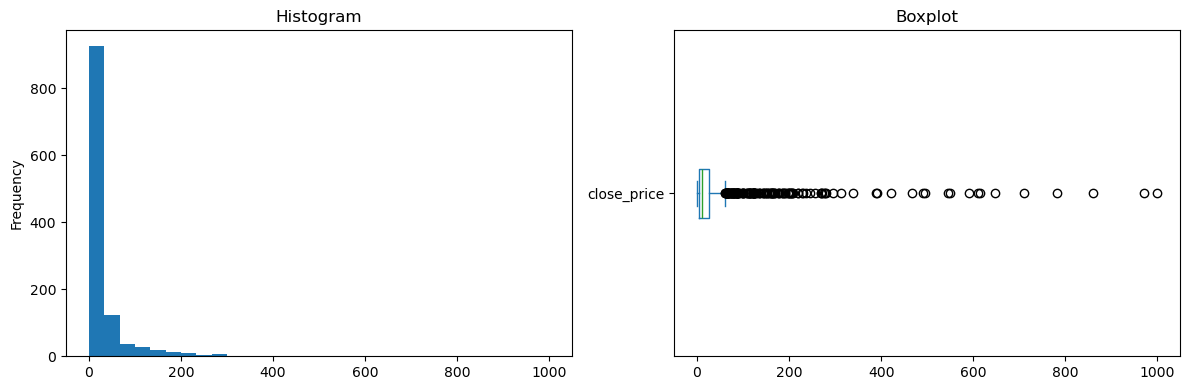

In [44]:
# close price
col = X_train["close_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

count    1183.000000
mean       12.520651
std        40.490395
min         0.010000
25%         1.230000
50%         4.440000
75%         9.990000
max       999.000000
Name: open_price, dtype: float64
skew: 15.323018628117001
missing: 0


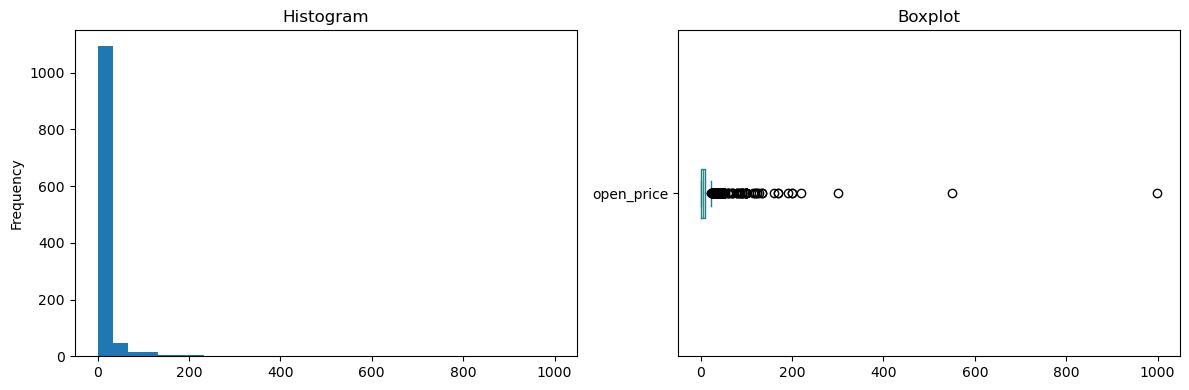

In [45]:
# open price
col = X_train["open_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

We conduct an initial distribution analysis to identify potential data quality issues, including numerical predictors with values outside their expected ranges and categorical predictors with inconsistent or non-standardized values.
However, no issues arise when observing the distributions of the variables. 

#### 1D: One-Hot Encoding
Dummy variables are created for the categorical predictors. Numerical predictors are not standardized for the decision tree model, as decision trees use threshold-based splits and are not sensitive to differences in feature scales. In contrast, kNN relies on distance calculations and is sensitive to feature scaling. Therefore, numerical predictors will be standardized when implementing the kNN model later in the analysis.

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "category",
    "currency",
    "end_day",
    "duration"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# Check processed dataset dimensions
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

# ensure response is 0,1 
y_train = y_train.astype(int)
y_test = y_test.astype(int)

Training shape: (1183, 36)
Testing shape: (789, 36)

Training target distribution:
competitive
1    639
0    544
Name: count, dtype: int64
(1183,)


## [2]: Initial Decision Tree

In [85]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz

In [83]:
!pip install graphviz

In [49]:
from sklearn.metrics import accuracy_score

In [80]:
from sklearn.tree import export_text

In [50]:
!pip install dmba

  Using cached dmba-0.2.4-py3-none-any.whl.metadata (1.9 kB)
Using cached dmba-0.2.4-py3-none-any.whl (11.8 MB)


In [51]:
from dmba import classificationSummary

no display found. Using non-interactive Agg backend


In [54]:
#set model hyperparameters
InitialTree = DecisionTreeClassifier(min_samples_leaf=50, random_state=42)

In [56]:
#Fit Decision Tree model
InitialTree.fit(X_train_encoded,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [62]:
#
classificationSummary(y_train, InitialTree.predict(X_train_encoded))

Confusion Matrix (Accuracy 0.8335)

       Prediction
Actual   0   1
     0 482  62
     1 135 504


In [72]:
#accuracy of training prediction
InitialTree.score(X_train_encoded, y_train)

0.8334742180896028

In [63]:
#
classificationSummary(y_test, InitialTree.predict(X_test_encoded))

Confusion Matrix (Accuracy 0.8200)

       Prediction
Actual   0   1
     0 311  51
     1  91 336


In [65]:
yprediction = InitialTree.predict(X_test_encoded)

In [69]:
#accuracy of testing prediction
InitialTree.score(X_test_encoded, y_test)

0.8200253485424588

Test accuracy is close to training accuracy, meaning that no obvious train and test performance gap.

In [74]:
InitialTree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 50,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [77]:
InitialTree.tree_.node_count

31

In [79]:
InitialTree.tree_.max_depth

6

In [81]:
feature_names = preprocessor.get_feature_names_out()

tree_rules = export_text(
    InitialTree,
    feature_names=list(feature_names)
)

print(tree_rules)

|--- remainder__open_price <= 3.72
|   |--- remainder__close_price <= 3.69
|   |   |--- remainder__open_price <= 1.04
|   |   |   |--- class: 1
|   |   |--- remainder__open_price >  1.04
|   |   |   |--- remainder__close_price <= 1.84
|   |   |   |   |--- class: 0
|   |   |   |--- remainder__close_price >  1.84
|   |   |   |   |--- remainder__seller_rating <= 2256.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- remainder__seller_rating >  2256.00
|   |   |   |   |   |--- class: 0
|   |--- remainder__close_price >  3.69
|   |   |--- remainder__open_price <= 2.46
|   |   |   |--- class: 1
|   |   |--- remainder__open_price >  2.46
|   |   |   |--- class: 1
|--- remainder__open_price >  3.72
|   |--- remainder__close_price <= 10.00
|   |   |--- remainder__open_price <= 4.93
|   |   |   |--- class: 0
|   |   |--- remainder__open_price >  4.93
|   |   |   |--- remainder__close_price <= 6.99
|   |   |   |   |--- remainder__close_price <= 5.99
|   |   |   |   |   |--- class: 0
|   |

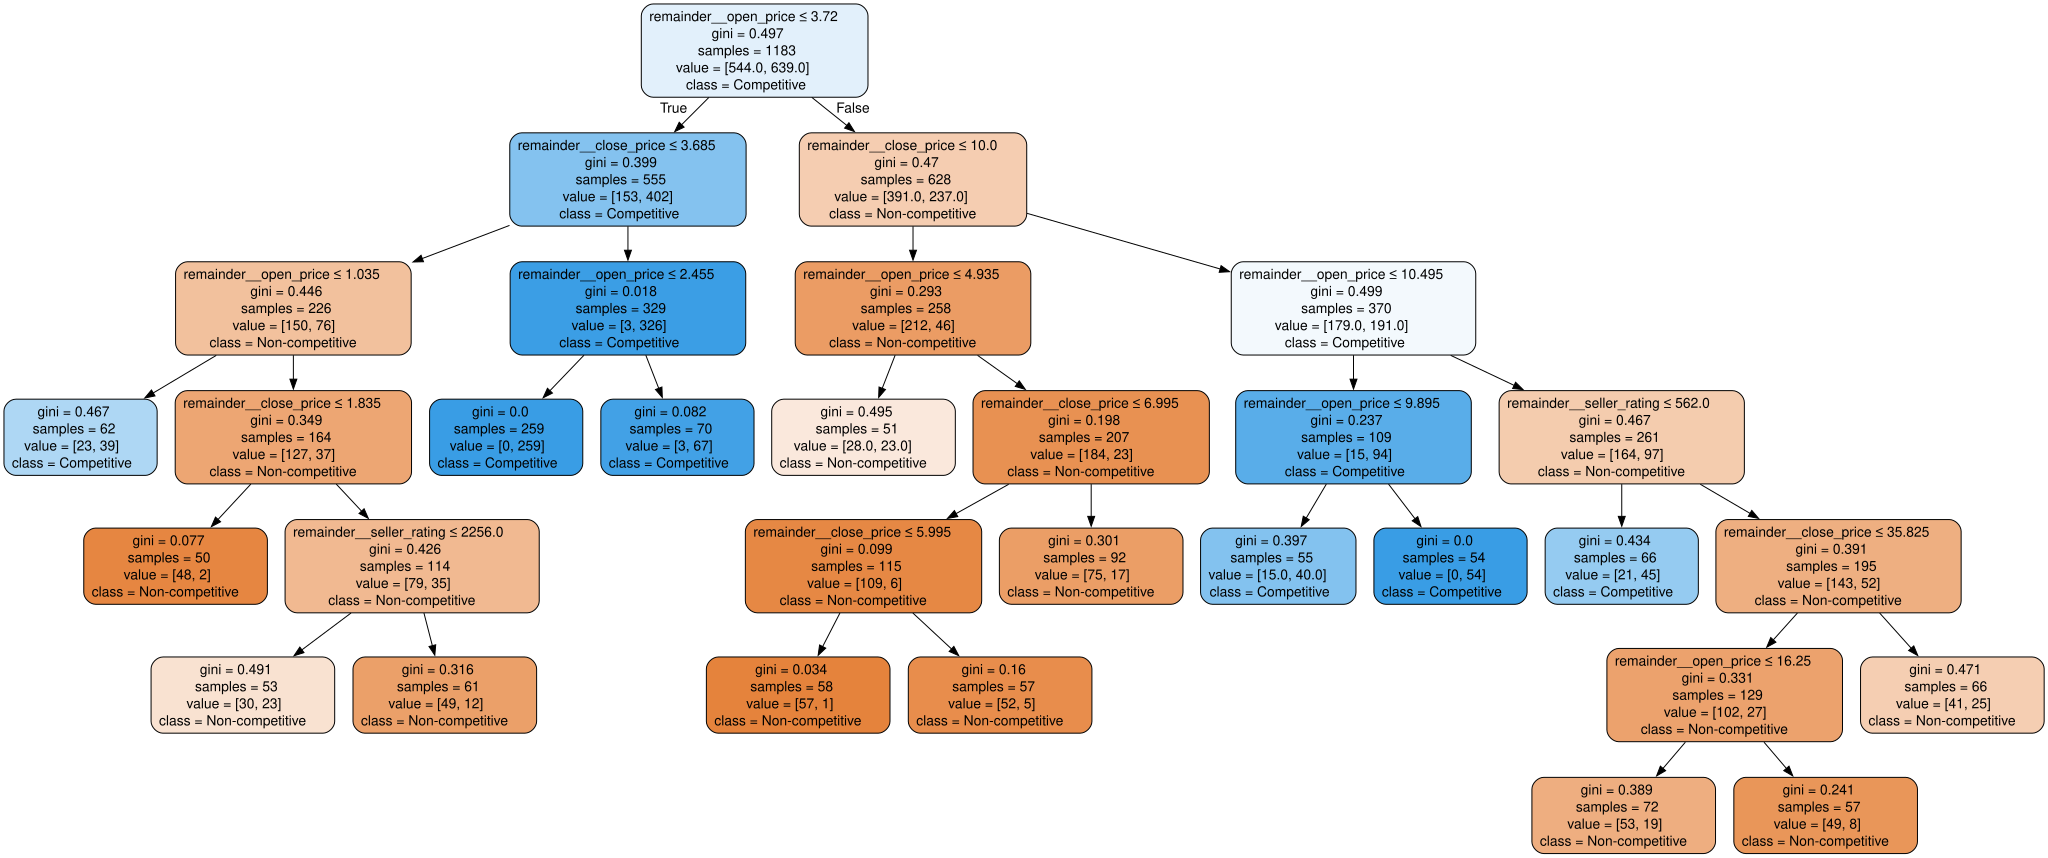

In [86]:
#plot decision tree
import graphviz
dot_data = export_graphviz(
    InitialTree,
    out_file=None,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["Non-competitive", "Competitive"],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)

display(graph)

### Initial Classification Tree: Rules and Interpretation

The initial classification tree was fitted using all available predictors, with a minimum of 50 observations per terminal node to limit overfitting. The resulting tree contains 31 nodes, including 16 terminal nodes, and has a maximum depth of six. The model achieved a training accuracy of 83.35% and a testing accuracy of 82.00%, suggesting relatively consistent predictive performance across the two datasets.

**Classification Rules**

The tree primarily relies on opening price and closing price, with seller rating appearing in a limited number of branches. The root node splits auctions at an opening price of 3.72.

Several notable classification rules emerge:

- Auctions with an opening price of 1.04 or less and a closing price of 3.69 or less are classified as competitive.
- Auctions with an opening price of 3.72 or less and a closing price above 3.69 are classified as competitive.
- Auctions with an opening price above 3.72 and a closing price of 10.00 or less are classified as non-competitive.
- Auctions with an opening price between 3.72 and 10.49 and a closing price above 10.00 are classified as competitive.

**Interesting and Unexpected Findings**

One unexpected finding is that higher seller ratings do not consistently correspond to competitive auctions. Under certain price conditions, auctions associated with lower-rated sellers are classified as competitive, suggesting that seller reputation does not necessarily dominate pricing-related factors in this model.

Additionally, product category, currency, auction duration, and ending day are not selected for any splits, indicating that they provide limited additional classification value under the current model settings.

**Less Surprising Findings**

The prominence of opening price is relatively intuitive, as the starting price may influence buyers' willingness to participate. Similarly, the importance of closing price is unsurprising because the final transaction price may reflect bidding activity.

**Potential Predictor Reduction**

If a small reduction in the number of predictors were required, variables not selected for any splits, such as currency, ending day, duration, or product category, would be reasonable candidates for removal. Their exclusion would simplify the model without changing the current fitted tree's decision rules, although the model should be refitted and evaluated to verify its performance.

Importantly, closing price is only observable after an auction ends. Therefore, despite its predictive value in the initial model, it should be excluded when developing a practical model for predicting the competitiveness of a new auction.